<div style="display: flex; justify-content: flex-start; align-items: center;">
    <a href="https://colab.research.google.com/github/msfasha/307307-BI-Methods-Generative-AI/blob/main/20261/Module%205%20-%20Planning%20and%20ReAct/Module5_Planning_ReAct_lab.ipynb" target="_blank">
        <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" style="height: 25px;">
    </a>
</div>

<div style="background:#F5EDF4; border-top:3px solid #A83296; padding:15px; border-radius:0 0 8px 8px">
<h1 style="color:#493347; margin:0">Lab — Planning & ReAct (Module 5)</h1>
<p style="color:#655263; margin:4px 0 0 0">Intro to Generative AI / Agentic AI — University of Petra</p>
</div>

**Course:** 307307 BI Methods for Generative AI (Agentic AI half)  
**Reference:** Grootendorst &amp; Alammar, *An Illustrated Guide to AI Agents* (O'Reilly, 2026), Chapter 6.

So far the agent acts **one step at a time**. Today we add the **ReAct loop** — THOUGHT, ACTION, OBSERVATION, repeated — so it can solve a **multi-step** problem on its own. This is the moment the TinyAgent becomes truly autonomous.

**This is a run-and-observe lab.** Run each cell and watch the agent reason step by step. One small exercise at the end.

<div align="center">
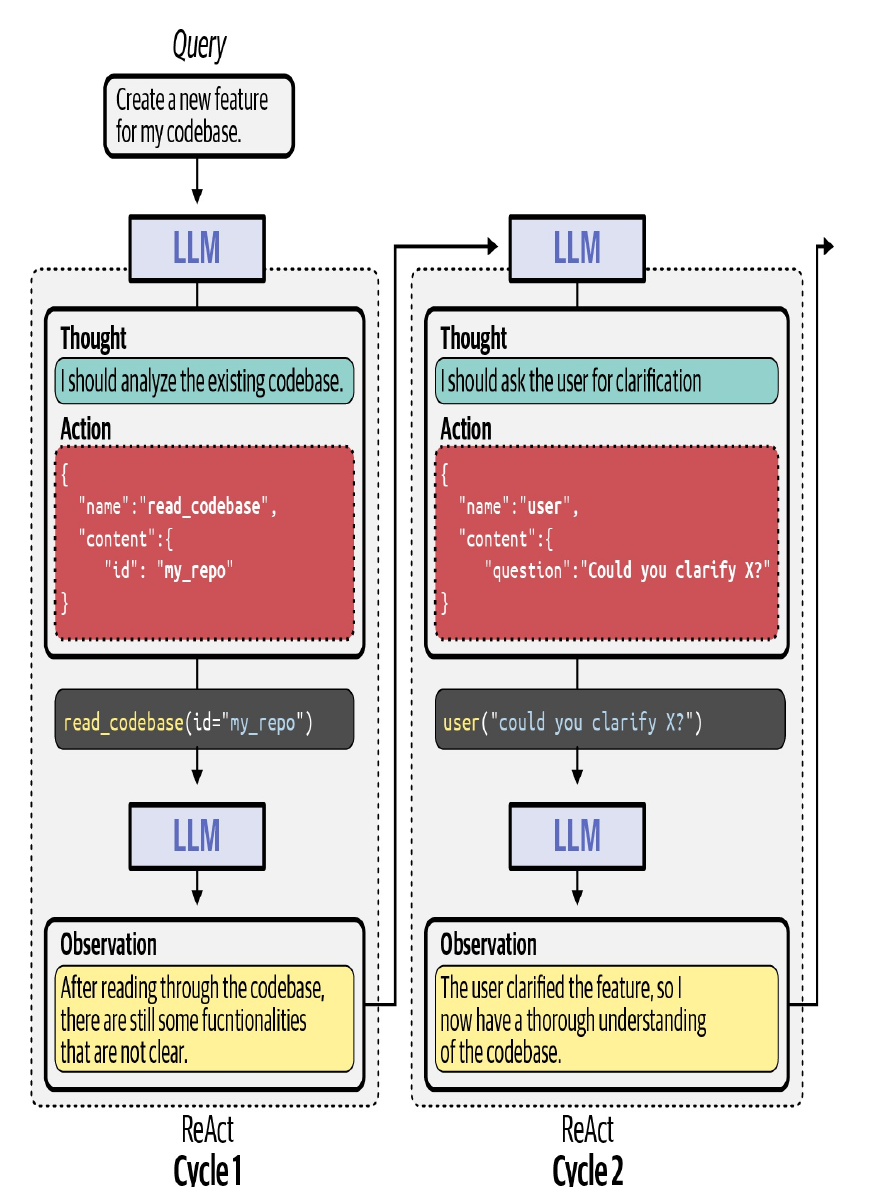
<br><span style="color:#6E6E6E; font-size:90%"><i>Two cycles of THOUGHT / ACTION / OBSERVATION (Figure 6-13). An Illustrated Guide to AI Agents (O'Reilly, 2026)</i></span>
</div>

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 0 — Setup (just run these)</h2>
</div>

Re-creates the brain and the tools from earlier modules so the notebook runs on its own.

In [ ]:
# In Google Colab, remove the leading # to install. Locally, run once.
# %pip install -q openai

In [ ]:
import os, json, re
from getpass import getpass
from openai import OpenAI

if not os.environ.get('GEMINI_API_KEY'):
    os.environ['GEMINI_API_KEY'] = getpass('Paste your Gemini API key (hidden): ')
MODEL = 'gemini-3.8-flash'
BASE_URL = 'https://generativelanguage.googleapis.com/v1beta/openai/'
client = OpenAI(api_key=os.environ['GEMINI_API_KEY'], base_url=BASE_URL)

def ask_llm(messages):
    r = client.chat.completions.create(model=MODEL, messages=messages, temperature=0.0)
    return r.choices[0].message.content or ''

# Tools from Module 4 (numbers arrive as strings because the LLM outputs text).
def add(a, b):      return str(float(a) + float(b))
def subtract(a, b): return str(float(a) - float(b))
def multiply(a, b): return str(float(a) * float(b))
TOOLS = {'add': add, 'subtract': subtract, 'multiply': multiply}
print('Ready. Model:', MODEL)

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 1 — The ReAct idea</h2>
</div>

ReAct repeats a simple cycle until the task is done:
- **THOUGHT** — the agent reasons about the next step.
- **ACTION** — it calls a tool.
- **OBSERVATION** — we run the tool and give back the result.

To stop, the agent calls a special `final_answer`. We also cap the loop with `max_steps` so it can never run forever. The whole thing is just a **for-loop** around an LLM call.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 2 — Build the ReAct agent</h2>
</div>

The system prompt teaches the format. Each turn we read the THOUGHT and the ACTION (a JSON tool call), run the tool, and feed back an OBSERVATION — looping until `final_answer`.

In [ ]:
REACT_PROMPT = '''You are a ReAct agent. Work in steps. Each turn, output EXACTLY:

THOUGHT: <your reasoning about the next step>
ACTION: {"tool": "<tool_name>", "kwargs": {<arguments>}}

Available tools:
- add: add(a, b)
- subtract: subtract(a, b)
- multiply: multiply(a, b)

When you have the final result, use:
ACTION: {"tool": "final_answer", "kwargs": {"answer": "<your answer>"}}
Do only ONE action per turn. Do not write the OBSERVATION yourself.'''


def parse_action(text):
    # Grab the JSON object after the first '{' (tolerates extra text around it).
    start, end = text.find('{'), text.rfind('}') + 1
    if start == -1 or end <= start:
        return None
    try:
        return json.loads(text[start:end])
    except json.JSONDecodeError:
        return None


def run_react(task, max_steps=6, verbose=True):
    messages = [{'role': 'system', 'content': REACT_PROMPT},
                {'role': 'user', 'content': task}]
    for step in range(1, max_steps + 1):
        reply = ask_llm(messages)
        call = parse_action(reply)
        thought = reply.split('ACTION')[0].replace('THOUGHT:', '').strip()
        if verbose and thought:
            print(f'Step {step} THOUGHT: {thought}')
        if call is None:
            return reply   # no structured action; just return the text
        if call['tool'] == 'final_answer':
            ans = call.get('kwargs', {})
            return ans.get('answer', ans) if isinstance(ans, dict) else ans
        if verbose: print(f'Step {step} ACTION: {call}')
        result = TOOLS[call['tool']](**call['kwargs']) if call['tool'] in TOOLS else f"unknown tool {call['tool']}"
        if verbose: print(f'Step {step} OBSERVATION: {result}\n')
        messages.append({'role': 'assistant', 'content': reply})
        messages.append({'role': 'user', 'content': f'OBSERVATION: {result}'})
    return 'Stopped: max_steps reached.'

print('ReAct agent ready.')

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Part 3 — Watch it solve a multi-step problem</h2>
</div>

Give it a problem that needs several tools in order: **(4.6 + 6.685) × 4, then subtract 3.14.** Watch it plan and work through one step at a time.

In [ ]:
answer = run_react('What is (4.6 + 6.685) times 4, and then subtract 3.14 from the result?')
print('FINAL ANSWER:', answer)

Notice the pattern: it **added**, then **multiplied** the result, then **subtracted** — each step using the previous observation — and finally called `final_answer`. No single tool could do this; the **loop** is what solved it. That loop is what makes it an agent.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Exercise</h2>
</div>

**Task A.** Run the agent on a different multi-step question, for example: *"Add 12 and 8, multiply the result by 5, then subtract 20."* Read the printed THOUGHT / ACTION / OBSERVATION steps.

**Task B (think, no code).** In a comment, say what `max_steps` protects against, and why an agent might otherwise loop forever.

Fill in the `# YOUR CODE HERE` line, then check the solution below.

In [ ]:
# YOUR CODE HERE
# Task A:
# print(run_react('Add 12 and 8, multiply the result by 5, then subtract 20.'))

# Task B (answer in a comment): what does max_steps protect against?
# Answer: ...

**Solution** (try it yourself first):

In [ ]:
# --- Solution ---
# Task A
print('FINAL ANSWER:', run_react('Add 12 and 8, multiply the result by 5, then subtract 20.'))

# Task B
# max_steps caps how many THOUGHT/ACTION/OBSERVATION cycles the agent may run. Without it,
# an agent that never decides to call final_answer (confused, or stuck repeating a step)
# would loop forever, wasting time and tokens. max_steps is a safety stop.

<div style="background:#F7F3F7; border-left:3px solid #C8ABC3; padding:10px; border-radius:0 5px 5px 0; margin-top:10px">
<h2 style="color:#493347; margin:0">Summary and what we built</h2>
</div>

Today you:
- Built the **ReAct loop**: THOUGHT -> ACTION -> OBSERVATION, repeated, with a `final_answer` stop and a `max_steps` cap.
- Watched the agent **decompose** a multi-step task and solve it autonomously.

```
TinyAgent/
  agent.py        <- updated: an autonomy for-loop
  planning.py     <- new: the ReAct planner
  llm.py  memory.py  tools.py  toolbox.py  trajectory.py
```

**Your single-agent TinyAgent is now complete:** reasoning (brain) + memory + tools + planning. Everything since Module 1 led here.

**Beyond a single agent** (course survey): evaluation, multi-agent systems, multimodal agents, and coding agents — see the slides.

**Further reading:** *An Illustrated Guide to AI Agents*, Chapter 6 (Planning & Reflection).